In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

# Create directories
os.makedirs("graphs", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

In [4]:
df = pd.read_csv("dataset/kolkata_weather_jan_june_2026.csv")

print("Dataset Shape:", df.shape)

display(df.head())

df.info()

Dataset Shape: (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


<class 'pandas.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   str    
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   str    
 12  sunset                       1827 non-null   str    
 13  sunshine_duration            

In [5]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Statistical summary
display(df.describe())

Missing values:
time                           0
weather_code                   0
temperature_2m_mean            0
temperature_2m_max             0
temperature_2m_min             0
precipitation_sum              0
rain_sum                       0
precipitation_hours            0
wind_speed_10m_max             0
wind_gusts_10m_max             0
wind_direction_10m_dominant    0
sunrise                        0
sunset                         0
sunshine_duration              0
city                           0
latitude                       0
longitude                      0
dtype: int64

Duplicate rows: 0


,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,latitude,longitude
count,1827.000000,1827.00000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1.827000e+03,1.827000e+03
mean,34.143952,26.26486,31.099234,22.477066,5.429119,5.429119,4.952928,13.782157,30.756596,192.212917,33185.460542,2.257260e+01,8.836390e+01
std,28.997216,4.05022,3.924558,4.847343,9.550693,9.550693,6.275264,5.106847,9.081119,100.165783,9824.134424,3.553686e-15,2.842949e-14
min,0.000000,15.00000,19.600000,10.200000,0.000000,0.000000,0.000000,4.500000,11.500000,0.000000,0.000000,2.257260e+01,8.836390e+01
25%,3.000000,23.40000,28.700000,18.600000,0.000000,0.000000,0.000000,10.000000,24.100000,135.000000,30684.495000,2.257260e+01,8.836390e+01
50%,51.000000,27.40000,31.300000,24.600000,0.400000,0.400000,2.000000,12.600000,29.500000,188.000000,36088.150000,2.257260e+01,8.836390e+01
75%,63.000000,29.10000,33.300000,26.200000,7.350000,7.350000,9.000000,16.600000,36.000000,258.000000,39550.540000,2.257260e+01,8.836390e+01
max,65.000000,35.20000,43.900000,30.600000,80.500000,80.500000,24.000000,44.000000,83.900000,360.000000,44569.280000,2.257260e+01,8.836390e+01


In [6]:
df['time'] = pd.to_datetime(df['time'])

# Sort chronologically
df = df.sort_values('time').reset_index(drop=True)

print(df['time'].dtype)

print("Starting date:", df['time'].min())
print("Ending date:", df['time'].max())

datetime64[us]
Starting date: 2021-06-30 00:00:00
Ending date: 2026-06-30 00:00:00


In [7]:
df = df.drop(
    columns=['city', 'latitude', 'longitude',
             'sunrise', 'sunset']
)

print(df.shape)
display(df.head())

(1827, 12)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,20837.76
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,21439.24
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,12291.52
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,29486.65
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,41145.46


In [8]:
df['target_temperature'] = (
    df['temperature_2m_mean'].shift(-1)
)

# Remove the final row because it has no next-day target
df = df.dropna().reset_index(drop=True)

In [9]:
df['month'] = df['time'].dt.month
df['day'] = df['time'].dt.day
df['day_of_week'] = df['time'].dt.dayofweek

# Cyclical encoding of month
df['month_sin'] = np.sin(
    2 * np.pi * df['month'] / 12
)

df['month_cos'] = np.cos(
    2 * np.pi * df['month'] / 12
)

In [10]:
features = [
    'weather_code',
    'temperature_2m_mean',
    'temperature_2m_max',
    'temperature_2m_min',
    'precipitation_sum',
    'rain_sum',
    'precipitation_hours',
    'wind_speed_10m_max',
    'wind_gusts_10m_max',
    'wind_direction_10m_dominant',
    'sunshine_duration',
    'month',
    'day',
    'day_of_week',
    'month_sin',
    'month_cos'
]

X = df[features]

y = df['target_temperature']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1826, 16)
Target shape: (1826,)


In [11]:
processed_df = X.copy()

processed_df['target_temperature'] = y

processed_df.to_csv(
    "dataset/processed_weather.csv",
    index=False
)

print("Preprocessed dataset saved!")

Preprocessed dataset saved!


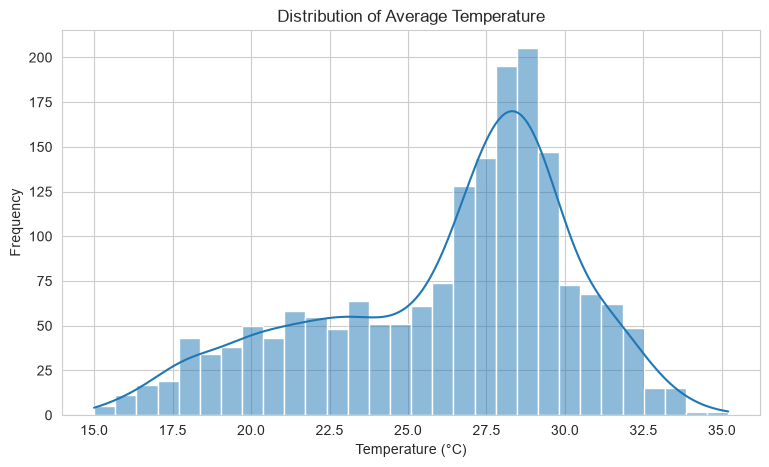

In [19]:
df = pd.read_csv("dataset/kolkata_weather_jan_june_2026.csv")
plt.figure(figsize=(9, 5))

sns.histplot(
    df['temperature_2m_mean'],
    bins=30,
    kde=True
)

plt.title("Distribution of Average Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Frequency")

plt.savefig("graphs/temperature_distribution.png")
plt.show()

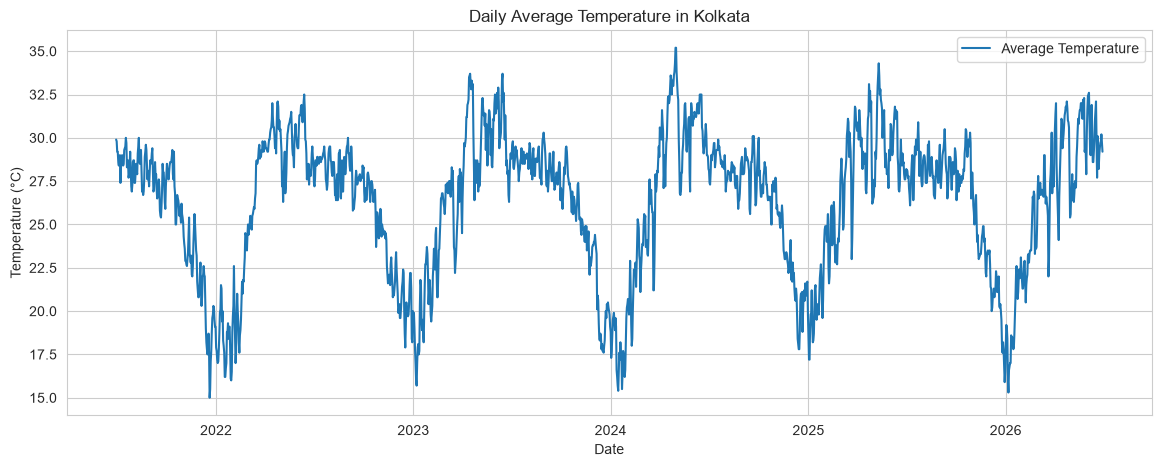

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(
    df['time'],
    df['temperature_2m_mean'],
    label='Average Temperature'
)

plt.title("Daily Average Temperature in Kolkata")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.legend()

plt.savefig("graphs/temperature_over_time.png")
plt.show()

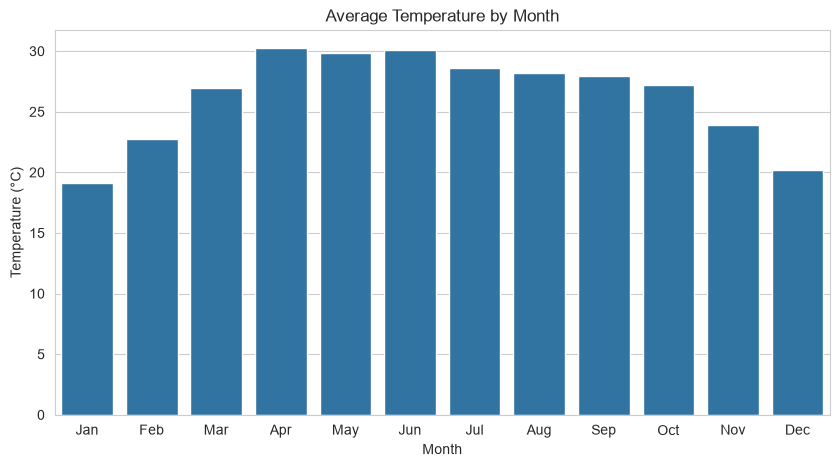

In [14]:
df['month_name'] = df['time'].dt.month_name()

monthly_temp = df.groupby(
    'month'
)['temperature_2m_mean'].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_temp.index,
    y=monthly_temp.values
)

plt.title("Average Temperature by Month")
plt.xlabel("Month")
plt.ylabel("Temperature (°C)")

plt.xticks(
    ticks=range(12),
    labels=[
        'Jan', 'Feb', 'Mar', 'Apr',
        'May', 'Jun', 'Jul', 'Aug',
        'Sep', 'Oct', 'Nov', 'Dec'
    ]
)

plt.savefig("graphs/monthly_temperature.png")
plt.show()

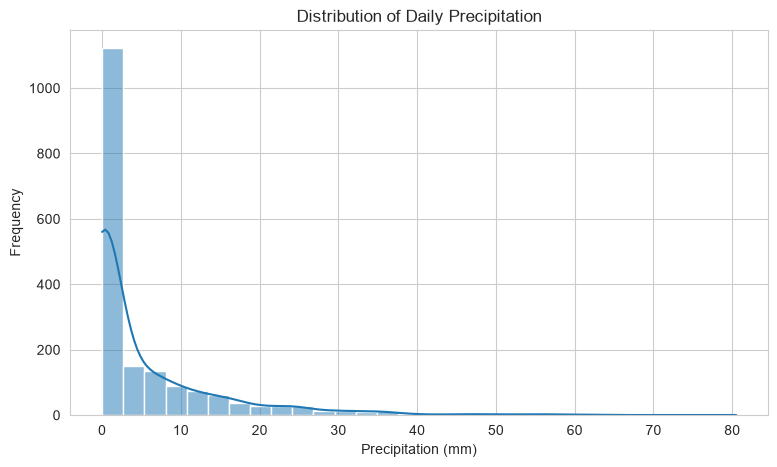

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df['precipitation_sum'],
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Precipitation")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")

plt.savefig("graphs/rainfall_distribution.png")
plt.show()

In [20]:
processed_df = pd.read_csv("dataset/processed_weather.csv")

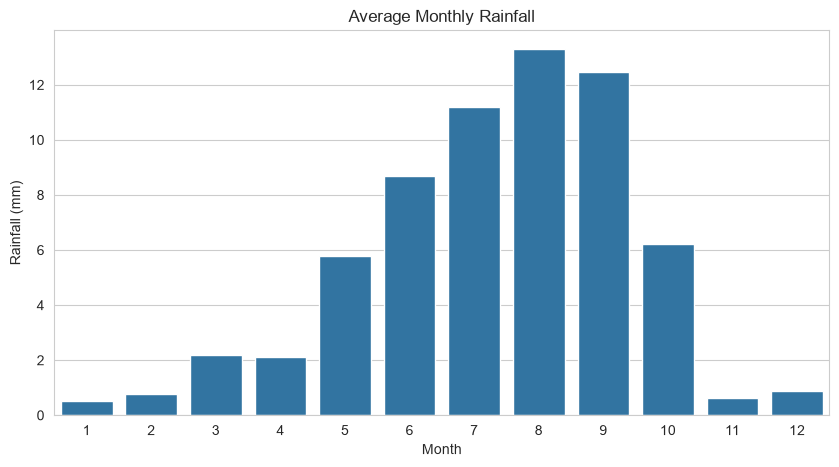

In [21]:
monthly_rainfall = processed_df.groupby(
    'month'
)['precipitation_sum'].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_rainfall.index,
    y=monthly_rainfall.values
)

plt.title("Average Monthly Rainfall")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.savefig("graphs/monthly_rainfall.png")
plt.show()

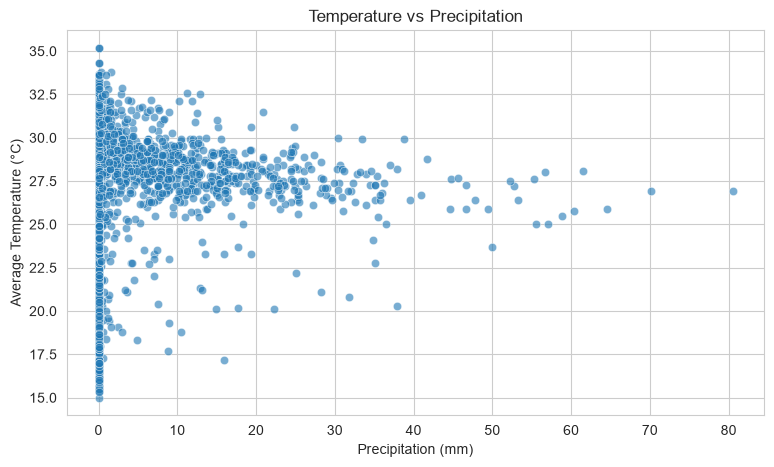

In [22]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='precipitation_sum',
    y='temperature_2m_mean',
    alpha=0.6
)

plt.title("Temperature vs Precipitation")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Average Temperature (°C)")

plt.savefig("graphs/temp_vs_rainfall.png")
plt.show()

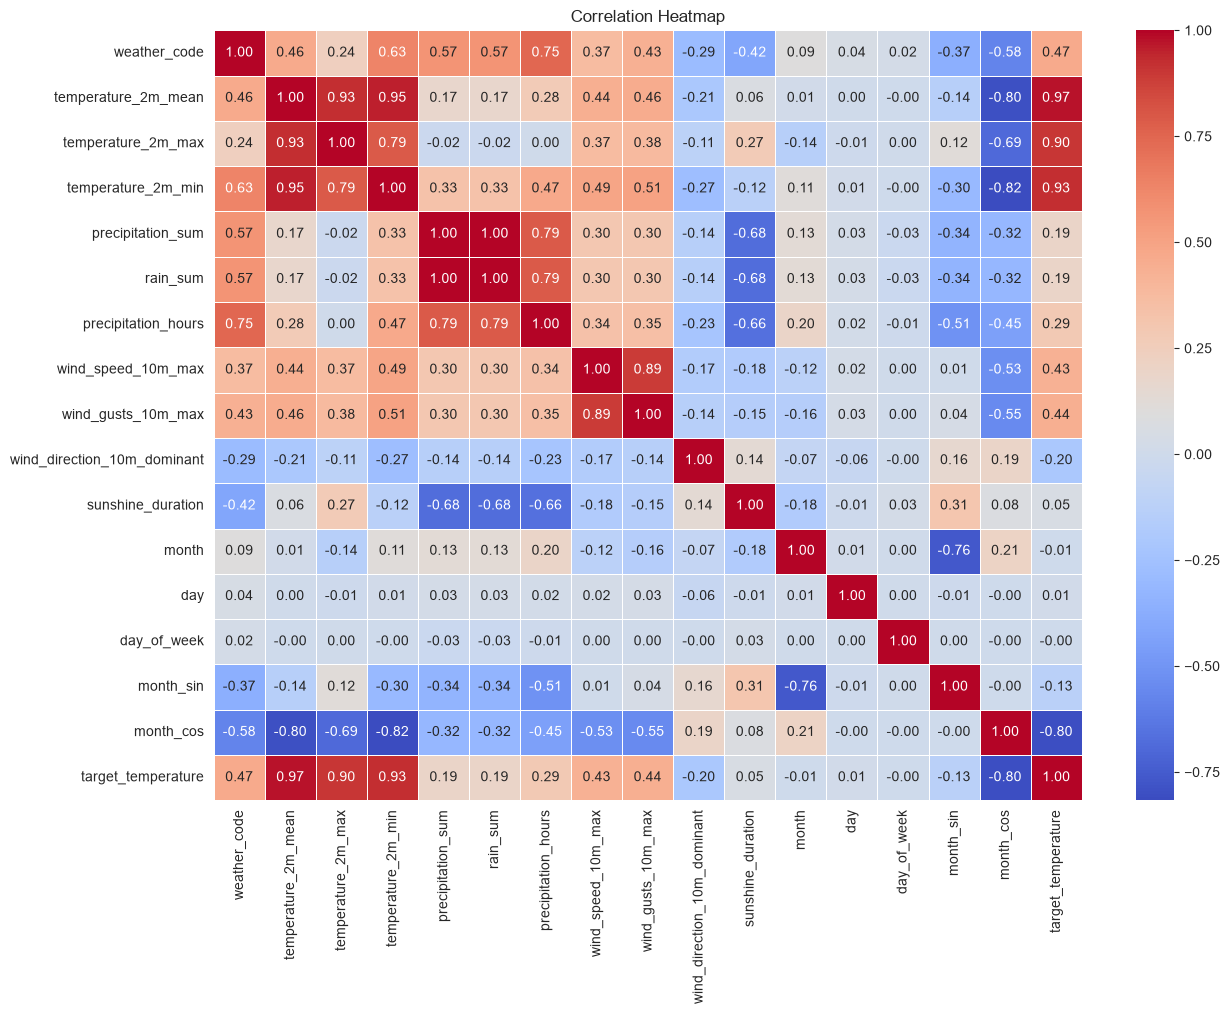

In [24]:
plt.figure(figsize=(14, 10))

corr = processed_df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.savefig(
    "graphs/correlation_heatmap.png",
    bbox_inches='tight'
)

plt.show()